In [16]:
from IPython.display import HTML, display
css_file_path = "../../design/custom.css"
styles = "<link rel='stylesheet' href='%s'>" % css_file_path
display(HTML(styles))

# 3.4 $\quad$ Portfolio Optimization with Short Selling

A **short position** is an investment strategy in which an investor sells an asset they do not currently own, with an agreement to buy it back in the future. The seller hopes to profit from a decline in the asset’s price. Consider the following example:

- `A` takes a short position in 500 IBM shares at `$120` per share, receiving `$60,000`.

- The broker identifies a customer `B` willing to act as the counterparty.

- Customer `B` delivers `$60,000`.

- `A` agrees to return the value of the 500 shares to `B` in July.

<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_3_Markowitz/imgs/posiciones_cortas_1.jpg" width="500">

- In May, a dividend of `$1` per share is paid.

- `A` must pay the broker `$500` for the 500 shares.

- The broker pays customer `B` `$500`.

<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_3_Markowitz/imgs/posiciones_cortas_2.jpg" width="500">

- In July, IBM is trading at `$100`, and customer `A` closes the short position.

- `A` pays the broker `100 × 500 = $50,000`.

- The broker pays `B` `$50,000`.

- The short position is closed.

<img src="https://raw.githubusercontent.com/alfonso-santos/microcredencial-carteras-python/Finance_Technology/Tema_3_Markowitz/imgs/posiciones_cortas_3.jpg" width="500">

The result of the short-selling transaction is as follows:

<img src="../imgs/posiciones_cortas_resultado.jpg">

* Source: Hull (2018)

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import yfinance as yf


plt.style.use('ggplot')

In [18]:
# Date range
start = '2015-01-01'
end = '2019-12-30'

# Assets (all with positive returns)
assets = ['BA', 'BAX', 'BMY', 'CMCSA', 'CNP', 'CPB', 'DE', 'F', 'GE', 'HPQ', 
        'JCI', 'JPM','KHC', 'LUV', 'MMC', 'MO', 'NI', 'PCAR', 'PSA', 'SEE', 
        'T', 'TGT', 'TMO','TXT', 'VZ', 'ZION']

# Downloading data
prices = yf.download(assets, start = start, end = end)['Close']


[**********************50%                       ]  13 of 26 completed$MMC: possibly delisted; no timezone found
[**********************69%********               ]  18 of 26 completed$SEE: possibly delisted; no timezone found
[*********************100%***********************]  26 of 26 completed

2 Failed downloads:
['MMC', 'SEE']: possibly delisted; no timezone found


<Axes: xlabel='Ticker'>

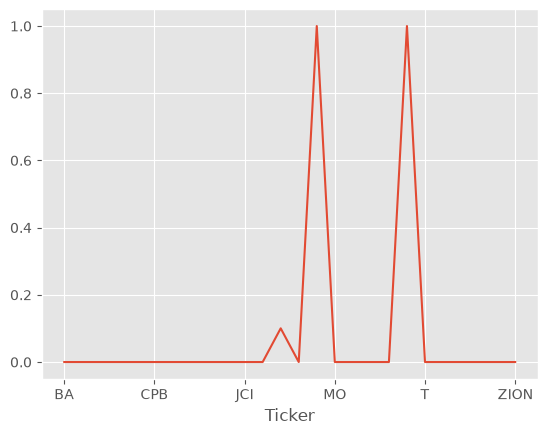

In [19]:
prices.isna().mean().plot()

In [20]:
prices = prices.loc[:, prices.isna().mean() <= 0.10]
assets = prices.columns

In [21]:
# Number of assets
num_act = prices.shape[1]
returns = np.log(prices / prices.shift(1)).dropna()
matriz_cov = returns.cov().to_numpy() # Covariance matrix
retornos_esperados = returns.mean().to_numpy() # Column vector expected return

First, we will construct the Markowitz efficient frontier without short selling. However, we will take a different approach: instead of varying risk aversion, we will calculate:

1. The minimum-risk portfolio, which identifies the starting point of the efficient frontier.
2. The risk of the asset with the highest expected return, which identifies the endpoint of the efficient frontier.
3. For a sequence of risk levels, the portfolio with the maximum expected return subject to each risk limit.

In [22]:
# 1. Minimum-risk portfolio

pesos = cp.Variable(num_act)
riesgo = cp.quad_form(pesos, matriz_cov)
ret = retornos_esperados @ pesos
objetivo = cp.Minimize(riesgo)

# Constraints
constraints = [pesos >= 0,
               cp.sum(pesos) == 1
               ]

prob = cp.Problem(objetivo, constraints)

res = prob.solve()

min_ret = ret.value
min_riesgo = np.sqrt(riesgo.value) # Starting point of the efficient frontier

In [23]:
# 2. Risk of the asset with the highest expected return
i_activo = np.argmax(retornos_esperados)
max_riesgo = np.sqrt(matriz_cov[i_activo, i_activo])

In [24]:
cp.installed_solvers()

['CLARABEL', 'SCS', 'SCIP', 'SCIPY', 'HIGHS', 'OSQP']

In [25]:
# 3. Vary the risk limit in equally spaced steps

retornos_res = []
riesgos_res = []
for riesgo_objetivo in np.linspace(min_riesgo, max_riesgo, 200):
    pesos = cp.Variable(num_act)
    riesgo = cp.quad_form(pesos, matriz_cov)
    ret = retornos_esperados @ pesos
    objetivo = cp.Maximize(ret)

    # Constraints
    constraints = [pesos >= 0,
                   cp.sum(pesos) == 1,
                   riesgo <= riesgo_objetivo**2
                   ]

    prob = cp.Problem(objetivo, constraints)

    res = prob.solve()
    retornos_res.append(ret.value)
    riesgos_res.append(np.sqrt(riesgo.value))

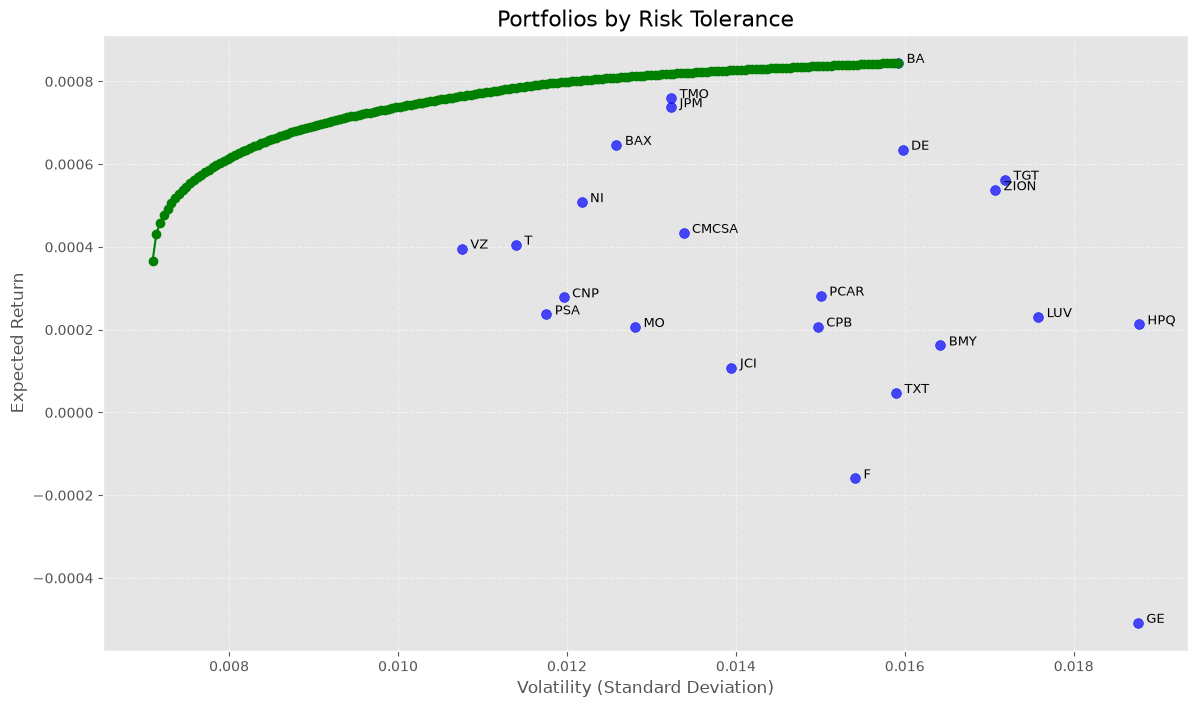

In [26]:
# Set the figure size and style
plt.figure(figsize=(14, 8))
plt.style.use('ggplot')

# Plot individual assets
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, label='Assets', alpha=0.7)

# Add asset labels with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00002  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)

plt.plot(riesgos_res, retornos_res, '-o', color='green')#,  alpha=0.3)   

# Add title and axis labels
plt.title('Portfolios by Risk Tolerance', fontsize=16)
plt.xlabel('Volatility (Standard Deviation)', fontsize=12)
plt.ylabel('Expected Return', fontsize=12)

# Add a legend in a suitable location
#plt.legend(loc='best')

# Show the grid for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Display the plot
plt.show()


## 1. Portfolios with Short Selling

### Portfolios with Short Selling and a Leverage Limit

The objective is to find the portfolio with the highest expected return while limiting short positions—that is, setting a maximum leverage limit (maximum short exposure). First, let us examine the expected returns of the individual assets:

Text(0.5, 1.0, 'Rentabilidad Esperada de los Assets')

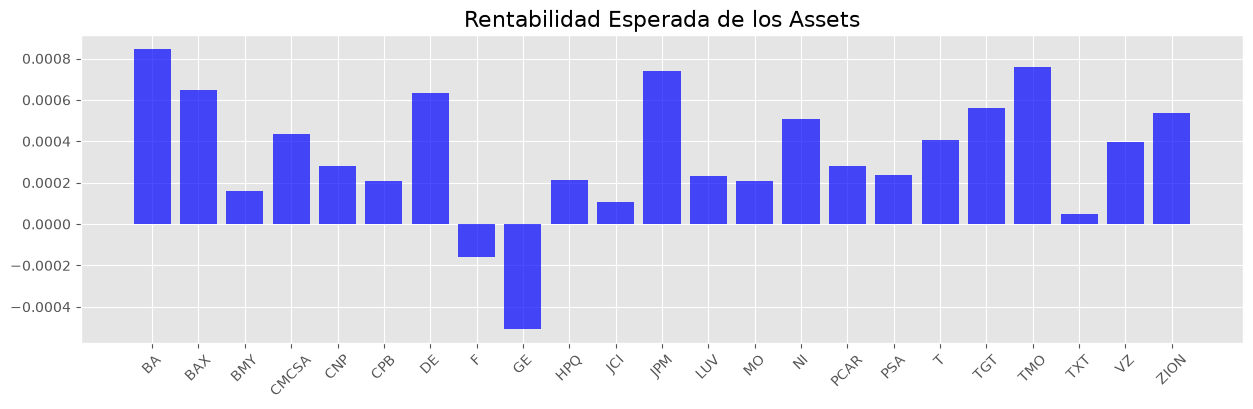

In [27]:
plt.figure(figsize=(15, 4))

plt.bar(range(len(retornos_esperados)), retornos_esperados, color='blue', alpha=0.7)

# Use asset names as x-axis tick labels
plt.xticks(range(len(assets)), assets, rotation=45)

plt.title('Rentabilidad Esperada de los Assets', fontsize=16)

## Exercise 1

As we can see, some assets in our universe have negative expected returns. If we **sell these assets short**, meaning we allow negative portfolio weights, their contribution to the portfolio’s expected return becomes positive. We will set a leverage limit of `450%`, so that the total absolute amount invested cannot exceed 500% of the investor’s capital.

In [30]:
pesos = cp.Variable(num_act)

# Constraints
constraints = [
    cp.sum(pesos) == 1,                 # Portfolio weights must sum to 1
    cp.sum(cp.abs(pesos)) <= 5.0        # Total absolute exposure must not exceed 500% of capital (leverage)
]

# Objective function (maximize expected return)
retorno_esperado = retornos_esperados @ pesos
objetivo = cp.Maximize(retorno_esperado)

# Define and solve the optimization problem
problema = cp.Problem(objetivo, constraints)
resultado = problema.solve()

riesgo = cp.quad_form(pesos, matriz_cov)

Let us plot the portfolio weights calculated by the optimizer, which allows short positions, alongside the expected returns shown previously:

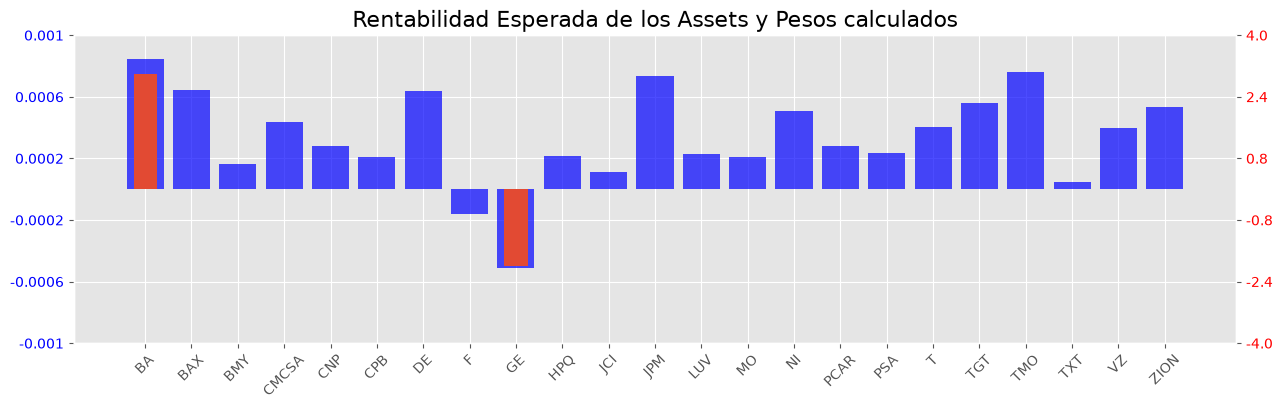

In [31]:
fig, ax = plt.subplots(figsize=(15, 4))

ax.bar(range(len(retornos_esperados)), retornos_esperados, color='blue', alpha=0.7)
ax2 = ax.twinx()
ax2.grid(False)
ax2.bar(range(num_act), pesos.value, width=0.5)

# Use asset names as x-axis tick labels
ax.set_xticks(range(len(assets)), assets, rotation=45)
ax.set_yticks(np.linspace(-1e-3, 1e-3, 6), np.around(np.linspace(-1e-3, 1e-3, 6), decimals=4), color="blue")
ax2.set_yticks(np.linspace(-4.0, 4.0, 6), np.around(np.linspace(-4.0, 4.0, 6), decimals=4), color="red")

ax.set_title('Rentabilidad Esperada de los Assets y Pesos calculados', fontsize=16)

ax.set_ylim(-1e-3, 1e-3)
ax2.set_ylim(-4.0, 4.0)
plt.show()

As shown in the figure, because portfolio risk is not constrained, the optimizer selects the asset with the highest positive expected return, `BA`, and combines it with the asset with the most negative expected return, `GE`.

In [32]:
pesos_ajustados = np.array([np.round(x, 3) if np.abs(x) > 10**-4 else 0  for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x != 0]

In [33]:
print(f'The assets included in the portfolio are {np.array(assets)[pesos_ajustados != 0].tolist()}')

print(f'The weights that maximize portfolio return are: {pesos_ajustados[pesos_ajustados != 0].round(2)}')

print(f'The returns of the assets included in the portfolio are: {retornos_esperados[pesos_ajustados != 0].round(4)}')

The assets included in the portfolio are ['BA', 'GE']
The weights that maximize portfolio return are: [ 3. -2.]
The returns of the assets included in the portfolio are: [ 0.0008 -0.0005]


Let us see where the portfolio we have just constructed lies:

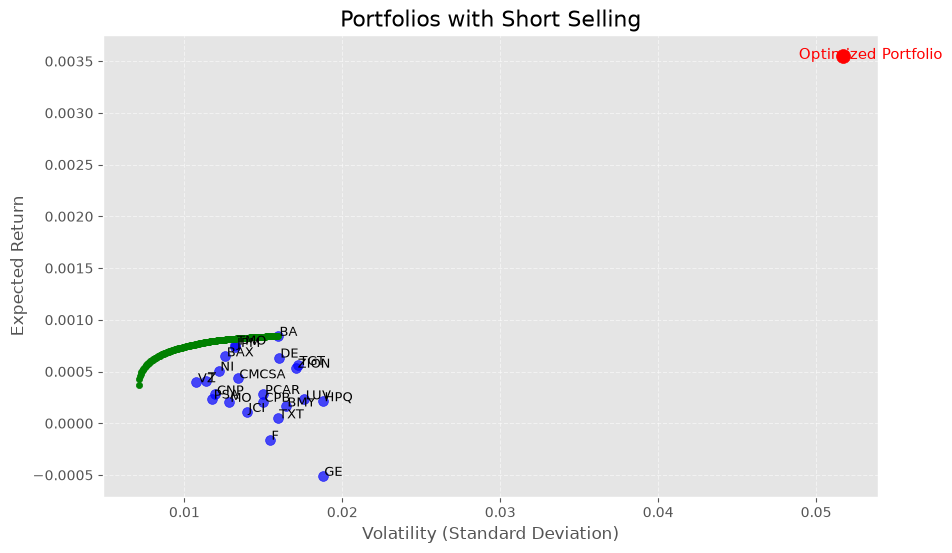

In [34]:
# Set the figure size and style
plt.figure(figsize=(10, 6))

# Plot individual assets
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, alpha=0.7)


# Add asset labels with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00003  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)



plt.scatter(np.sqrt(riesgo.value), resultado, color='red', s=100, marker='o')
plt.text(np.sqrt(riesgo.value) - 28*desplazamiento_x, resultado - desplazamiento_y, 'Optimized Portfolio', fontsize=11, color='red')

plt.scatter(riesgos_res, retornos_res, color='green', s=20, marker='o')


# Add title and axis labels
plt.title('Portfolios with Short Selling', fontsize=16)
plt.xlabel('Volatility (Standard Deviation)', fontsize=12)
plt.ylabel('Expected Return', fontsize=12)

# Add a legend in a suitable location
#plt.legend(loc='best')

# Show the grid for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Display the plot
plt.show()

---

### Maximum-*Expected-Return Portfolio for Different Risk Tolerances*, Varying the Permitted Short-Selling Leverage Limit

In [35]:
cortas_max = [1.0, 1.3, 1.5, 1.7, 2.0] # Maximum permitted leverage
resultados_df = pd.DataFrame()
num_sim = 100

In [36]:
for deuda in cortas_max: #
    riesgos_res_short = np.zeros(num_sim) # Risks
    retornos_res_short = np.zeros(num_sim) # Returns
    gamma_vals = np.logspace(-2, 3, num=num_sim) # Gamma values representing risk aversion

    for i in range(num_sim): 
        pesos = cp.Variable(num_act)
        gamma = cp.Parameter(nonneg=True)
        gamma.value = gamma_vals[i]
        
        ret = retornos_esperados.T @ pesos
        riesgo = cp.quad_form(pesos, matriz_cov)
        objetivo = cp.Maximize(ret - gamma * riesgo)

        constraints = [cp.sum(pesos) == 1,
                       cp.sum(cp.abs(pesos)) <= deuda]
        prob = cp.Problem(objetivo, constraints)
        prob.solve()

        # Check the optimization problem status
        if prob.status not in ["infeasible", "unbounded"]:
            retornos_res_short[i] = ret.value
            riesgos_res_short[i] = cp.sqrt(riesgo).value
        else:
            print(f"Problem not solved for gamma={gamma.value}: {prob.status}")

    resultados_df[f'riesgo_{deuda}'] = riesgos_res_short
    resultados_df[f'retorno_{deuda}'] = retornos_res_short

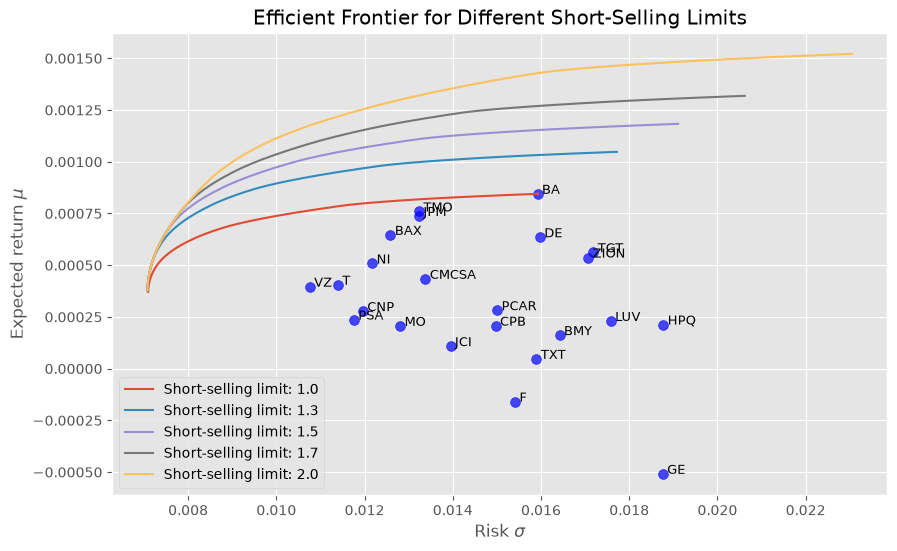

In [39]:
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

# Plot individual assets
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, alpha=0.7)

# Add asset labels with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00003  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)

for deuda in cortas_max:
    plt.plot(resultados_df[f'riesgo_{deuda}'], resultados_df[f'retorno_{deuda}'], label=f'Short-selling limit: {deuda}')

plt.xlabel(r'Risk $\sigma$')
plt.ylabel(r'Expected return $\mu$')
plt.title('Efficient Frontier for Different Short-Selling Limits')
plt.legend(loc='best')
plt.show()

---

### Exercise 2

Calculate the *maximum-expected-return* portfolio subject to a risk (volatility) limit of `0.014` and a maximum short position of `20%` in any single asset.

In [40]:
riesgo_obj = 0.014**2
peso_min = -0.2 # Minimum permitted weight

pesos = cp.Variable(num_act)
riesgo = cp.quad_form(pesos, matriz_cov)


# Constraints
constraints = [
    cp.sum(pesos) == 1,                 # Portfolio weights must sum to 1
    riesgo <= riesgo_obj,               # Risk must not exceed the target risk
    pesos >= peso_min                   # Maximum short position is -0.2
]

# Objective function (maximize expected return)
retorno = retornos_esperados @ pesos
objetivo = cp.Maximize(retorno)

# Define and solve the optimization problem
problema = cp.Problem(objetivo, constraints)
resultado = problema.solve()

In [41]:
# Save the optimized portfolio for plotting

max_cortos = np.array([np.sqrt(riesgo.value), retorno.value])
max_cortos

array([0.014    , 0.0017112])

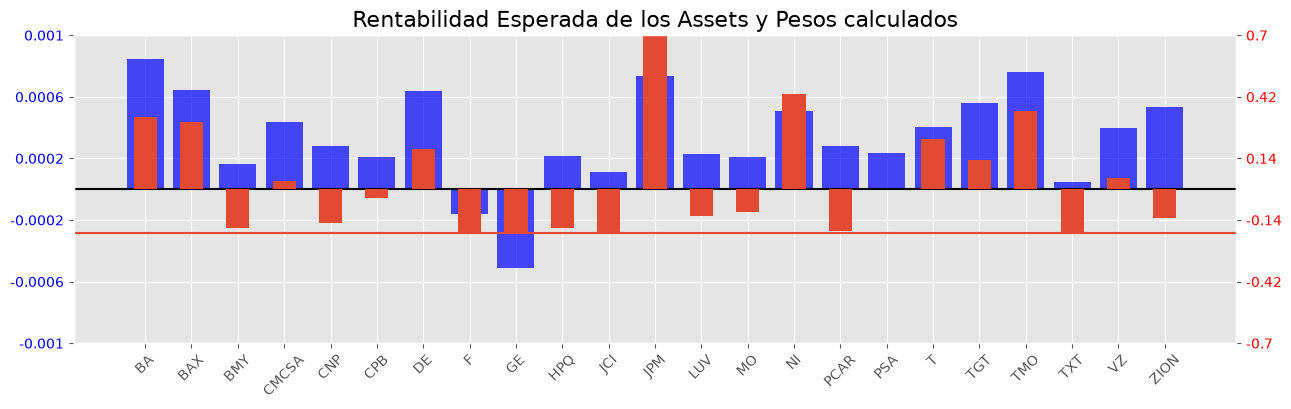

In [42]:
fig, ax = plt.subplots(figsize=(15, 4))

ax.bar(range(len(retornos_esperados)), retornos_esperados, color='blue', alpha=0.7)
ax2 = ax.twinx()
ax2.grid(False)
ax2.bar(range(num_act), pesos.value, width=0.5)

# Use asset names as x-axis tick labels
ax.set_xticks(range(len(assets)), assets, rotation=45)
ax.set_yticks(np.linspace(-1e-3, 1e-3, 6), np.around(np.linspace(-1e-3, 1e-3, 6), decimals=4), color="blue")
ax.axhline(0.0, color="black")
ax2.set_yticks(np.linspace(-0.7, 0.7, 6), np.around(np.linspace(-0.7, 0.7, 6), decimals=4), color="red")
ax2.axhline(-0.2)

ax.set_title('Rentabilidad Esperada de los Assets y Pesos calculados', fontsize=16)

ax.set_ylim(-1e-3, 1e-3)
ax2.set_ylim(-0.7, 0.7)
plt.show()

Now let us calculate the **equivalent portfolio without short selling** so that we can compare the two.

In [44]:
riesgo_obj = 0.014**2

pesos = cp.Variable(num_act)
riesgo = cp.quad_form(pesos, matriz_cov)


# Constraints
constraints = [
    cp.sum(pesos) == 1,                 # Portfolio weights must sum to 1
    riesgo <= riesgo_obj,               # Risk must not exceed the target risk
    pesos >= 0.0                        # Minimum weight is 0.0 (no short selling)
]

# Objective function (maximize expected return)
retorno = retornos_esperados @ pesos
objetivo = cp.Maximize(retorno)

# Define and solve the optimization problem
problema = cp.Problem(objetivo, constraints)
resultado = problema.solve()

In [45]:
# Save the optimized portfolio for plotting

max_sin_cortos = np.array([np.sqrt(riesgo.value), retorno.value])
max_sin_cortos

array([0.014     , 0.00082731])

In [46]:
# Set very small weights (below 10**-4) to zero

pesos_ajustados = np.array([np.round(x, 3) if np.abs(x) > 10**-4 else 0  for x in pesos.value])

activos_filtrados = [asset for i, asset in enumerate(assets) if pesos_ajustados[i] > 0]
pesos_filtrados = [x for x in pesos_ajustados if x != 0]

In [47]:
print(f'The assets included in the portfolio are {np.array(assets)[pesos_ajustados != 0].tolist()}')

print(f'The weights that maximize portfolio return are: {pesos_ajustados[pesos_ajustados != 0].round(2)}')

The assets included in the portfolio are ['BA', 'TMO']
The weights that maximize portfolio return are: [0.79 0.21]


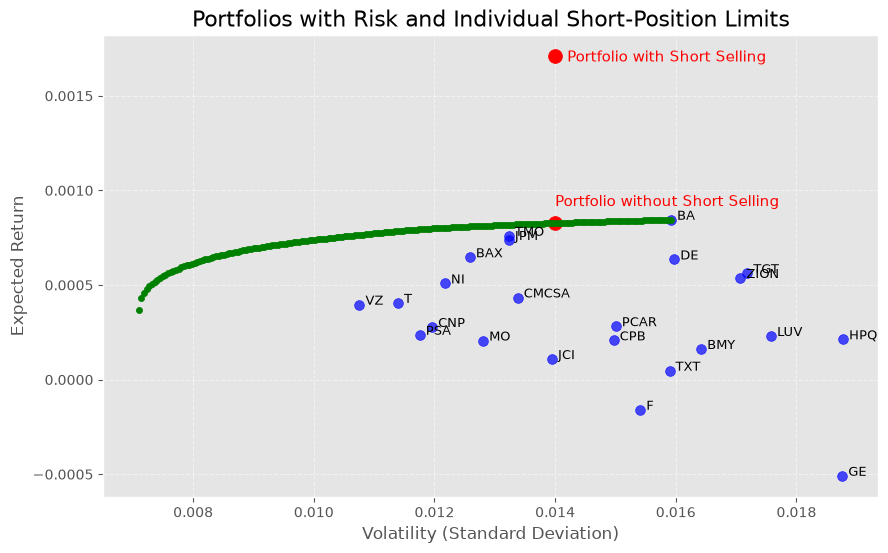

In [48]:
# Set the figure size and style
plt.figure(figsize=(10, 6))
plt.style.use('ggplot')

# Plot individual assets
plt.scatter(np.sqrt(np.diag(matriz_cov)), retornos_esperados, color='blue', s=50, alpha=0.7)


# Add asset labels with an offset
desplazamiento_x = 0.0001  # Adjust this value if necessary
desplazamiento_y = 0.00003  # Adjust this value if necessary

for i, asset in enumerate(assets):
    plt.text(np.sqrt(matriz_cov[i, i]) + desplazamiento_x, retornos_esperados[i] , asset, fontsize=9)



plt.scatter(max_cortos[0], max_cortos[1], color='red', s=100, marker='o')
plt.text(max_cortos[0] + 2*desplazamiento_x, max_cortos[1] - desplazamiento_y, 'Portfolio with Short Selling', fontsize=11, color='red')

plt.scatter(max_sin_cortos[0], max_sin_cortos[1], color='red', s=100, marker='o')
plt.text(max_sin_cortos[0] , max_sin_cortos[1] + 3 * desplazamiento_y, 'Portfolio without Short Selling', fontsize=11, color='red')

plt.scatter(riesgos_res, retornos_res, color='green', s=20, marker='o')


# Add title and axis labels
plt.title('Portfolios with Risk and Individual Short-Position Limits', fontsize=16)
plt.xlabel('Volatility (Standard Deviation)', fontsize=12)
plt.ylabel('Expected Return', fontsize=12)

# Add a legend in a suitable location
#plt.legend(loc='best')

# Show the grid for readability
plt.grid(True, linestyle='--', alpha=0.5)

# Display the plot
plt.show()